# Bài tập E3: LSTM / GRU trên chuỗi ảnh — Fashion-MNIST
**Môn học:** Học sâu và Ứng dụng trong Thị giác Máy tính (CO5085)  
**Sinh viên:** Nguyễn Trần Phước (MSSV: 2470576)

## 1. Thiết lập Môi trường

In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = "./outputs_e3"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Device: {device}")

Device: cuda


## 2. Tải dữ liệu Fashion-MNIST & Chia tập Train / Val / Test

In [2]:
BATCH_SIZE = 64
VAL_RATIO = 0.1
DATA_DIR = "./data"

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train_ds = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True, transform=transform)

val_size = int(len(full_train_ds) * VAL_RATIO)
train_size = len(full_train_ds) - val_size
generator = torch.Generator().manual_seed(SEED)
train_ds, val_ds = random_split(full_train_ds, [train_size, val_size], generator=generator)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")

100%|██████████| 26.4M/26.4M [00:03<00:00, 6.77MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 90.2kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 2.13MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.9MB/s]

Train: 54,000 | Val: 6,000 | Test: 10,000


## 3. Hai cách biểu diễn ảnh thành chuỗi + Mô hình LSTM/GRU & Baseline MLP/CNN

- **Row sequence**: mỗi hàng pixel (28 chiều) là một bước thời gian → chuỗi dài 28.
- **Patch sequence**: chia ảnh thành patch 4x4 không chồng lấp, quét theo thứ tự hàng/cột → chuỗi dài 49, mỗi bước là vector 16 chiều.
- **Baseline không hồi quy**: MLP và CNN (kiến trúc giống hệt E1) để so sánh.

In [3]:
PATCH_SIZE = 4


def image_to_row_sequence(x: torch.Tensor) -> torch.Tensor:
    """(B, 1, 28, 28) -> (B, seq_len=28, input_size=28), mỗi hàng ảnh là 1 bước thời gian."""
    return x.squeeze(1)


def image_to_patch_sequence(x: torch.Tensor, patch_size: int = PATCH_SIZE) -> torch.Tensor:
    """(B, 1, 28, 28) -> (B, seq_len=49, input_size=16), quét patch 4x4 theo thứ tự hàng/cột."""
    b = x.size(0)
    patches = x.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
    return patches.contiguous().view(b, -1, patch_size * patch_size)


class RecurrentClassifier(nn.Module):
    """Phân loại ảnh bằng cách coi ảnh như chuỗi (hàng pixel hoặc chuỗi patch), dùng nn.LSTM/nn.GRU."""

    def __init__(self, rnn_type="lstm", sequence_type="row", hidden_size=128, num_layers=1, num_classes=10, dropout=0.0):
        super().__init__()
        if sequence_type not in ("row", "patch"):
            raise ValueError(f"Unknown sequence_type: {sequence_type}")
        self.sequence_type = sequence_type
        input_size = 28 if sequence_type == "row" else PATCH_SIZE * PATCH_SIZE

        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU}[rnn_type.lower()]
        self.rnn = rnn_cls(
            input_size=input_size, hidden_size=hidden_size, num_layers=num_layers,
            batch_first=True, dropout=dropout if num_layers > 1 else 0.0
        )
        self.classifier = nn.Linear(hidden_size, num_classes)

    def to_sequence(self, x):
        if self.sequence_type == "row":
            return image_to_row_sequence(x)
        return image_to_patch_sequence(x)

    def forward(self, x):
        seq = self.to_sequence(x)
        out, _ = self.rnn(seq)
        return self.classifier(out[:, -1, :])


class MLPClassifier(nn.Module):
    def __init__(self, num_classes=10, dropout=0.2):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(28 * 28, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(self.flatten(x))


class CNNClassifier(nn.Module):
    def __init__(self, num_classes=10, dropout=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(inplace=True), nn.Dropout(dropout), nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def get_model(name, sequence_type="row", num_classes=10, hidden_size=128, num_layers=1):
    key = name.lower()
    if key in ("lstm", "gru"):
        return RecurrentClassifier(rnn_type=key, sequence_type=sequence_type, hidden_size=hidden_size, num_layers=num_layers, num_classes=num_classes)
    if key == "mlp":
        return MLPClassifier(num_classes)
    if key == "cnn":
        return CNNClassifier(num_classes)
    raise ValueError(f"Unknown model: {name}")


for rnn_type in ("lstm", "gru"):
    for seq_type in ("row", "patch"):
        m = get_model(rnn_type, sequence_type=seq_type)
        print(f"{rnn_type.upper():<5} | seq={seq_type:<6} | Params: {count_parameters(m):,}")
print(f"MLP   | Params: {count_parameters(get_model('mlp')):,}")
print(f"CNN   | Params: {count_parameters(get_model('cnn')):,}")

LSTM  | seq=row    | Params: 82,186
LSTM  | seq=patch  | Params: 76,042
GRU   | seq=row    | Params: 61,962
GRU   | seq=patch  | Params: 57,354
MLP   | Params: 235,914
CNN   | Params: 421,738


## 4. Huấn luyện và Đánh giá: Baseline (MLP, CNN) và LSTM/GRU (Row, Patch)

In [4]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device, transform_fn=None):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if transform_fn is not None:
            images = transform_fn(images)
        logits = model(images)
        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return running_loss / total, correct / total, np.array(all_preds), np.array(all_labels)


def flip_rows(images: torch.Tensor) -> torch.Tensor:
    """Đảo thứ tự các hàng của ảnh -> phá vỡ thứ tự chuỗi mà RNN đã học (kiểm tra phụ thuộc thời gian)."""
    return torch.flip(images, dims=[2])


EPOCHS = 15
LR = 1e-3
HIDDEN_SIZE = 128
NUM_LAYERS = 1

runs = [("mlp", "row", "MLP"), ("cnn", "row", "CNN")]
for rnn_type in ("lstm", "gru"):
    for seq_type in ("row", "patch"):
        runs.append((rnn_type, seq_type, f"{rnn_type.upper()}-{seq_type}"))

history, summary_results, order_sensitivity = {}, [], []

for model_key, sequence_type, display_name in runs:
    print(f"\n{'='*55}\nTraining: {display_name}\n{'='*55}")
    model = get_model(model_key, sequence_type=sequence_type, num_classes=len(CLASS_NAMES),
                       hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS).to(device)
    num_params = count_parameters(model)
    print(f"Trainable Parameters: {num_params:,}")

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)

    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_state = 0.0, None
    start_time = time.time()

    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion, device)

        h["train_loss"].append(tr_loss)
        h["val_loss"].append(va_loss)
        h["train_acc"].append(tr_acc)
        h["val_acc"].append(va_acc)

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc*100:.2f}% | "
              f"Val Loss: {va_loss:.4f} | Val Acc: {va_acc*100:.2f}%")

    train_time = time.time() - start_time
    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    test_loss, test_acc, preds, labels = evaluate(model, test_loader, criterion, device)
    print(f"--> Test ({display_name}): Loss = {test_loss:.4f} | Acc = {test_acc*100:.2f}% | Time = {train_time:.1f}s")

    _, flipped_acc, _, _ = evaluate(model, test_loader, criterion, device, transform_fn=flip_rows)

    history[display_name] = h
    summary_results.append({
        "Model": display_name, "Params": num_params,
        "Best Val Acc (%)": round(best_val_acc * 100, 2),
        "Test Acc (%)": round(test_acc * 100, 2),
        "Test Loss": round(test_loss, 4),
        "Time (s)": round(train_time, 1)
    })
    order_sensitivity.append({
        "Model": display_name,
        "Original Test Acc (%)": round(test_acc * 100, 2),
        "Row-Flipped Test Acc (%)": round(flipped_acc * 100, 2),
        "Drop (pp)": round((test_acc - flipped_acc) * 100, 2)
    })


Training: MLP
Trainable Parameters: 235,914
Epoch [01/15] Train Loss: 0.5036 | Train Acc: 82.38% | Val Loss: 0.3834 | Val Acc: 86.17%
Epoch [02/15] Train Loss: 0.3856 | Train Acc: 86.02% | Val Loss: 0.3410 | Val Acc: 87.55%
Epoch [03/15] Train Loss: 0.3538 | Train Acc: 87.07% | Val Loss: 0.3696 | Val Acc: 85.82%
Epoch [04/15] Train Loss: 0.3308 | Train Acc: 87.68% | Val Loss: 0.3368 | Val Acc: 87.87%
Epoch [05/15] Train Loss: 0.3154 | Train Acc: 88.22% | Val Loss: 0.3175 | Val Acc: 88.17%
Epoch [06/15] Train Loss: 0.3060 | Train Acc: 88.63% | Val Loss: 0.3488 | Val Acc: 87.07%
Epoch [07/15] Train Loss: 0.2949 | Train Acc: 88.91% | Val Loss: 0.3085 | Val Acc: 88.73%
Epoch [08/15] Train Loss: 0.2880 | Train Acc: 89.31% | Val Loss: 0.3067 | Val Acc: 88.68%
Epoch [09/15] Train Loss: 0.2784 | Train Acc: 89.68% | Val Loss: 0.3079 | Val Acc: 88.62%
Epoch [10/15] Train Loss: 0.2737 | Train Acc: 89.83% | Val Loss: 0.3013 | Val Acc: 89.30%
Epoch [11/15] Train Loss: 0.2679 | Train Acc: 89.98% | 

## 5. Bảng Tổng hợp & Learning Curves

,Model,Params,Best Val Acc (%),Test Acc (%),Test Loss,Time (s)
0,MLP,235914,89.68,88.57,0.3174,206.6
1,CNN,421738,92.95,92.08,0.2372,213.8
2,LSTM-row,82186,89.47,88.76,0.3067,212.4
3,LSTM-patch,76042,88.02,87.11,0.3528,212.4
4,GRU-row,61962,90.75,90.06,0.2771,252.2
5,GRU-patch,57354,88.60,87.97,0.3342,229.7


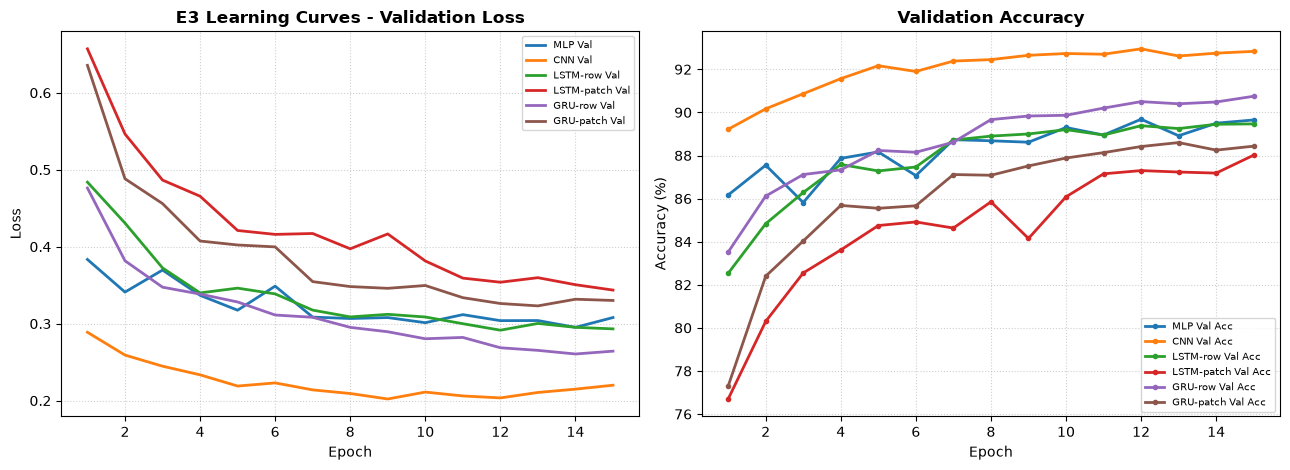

In [5]:
df_summary = pd.DataFrame(summary_results)
display(df_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, h in history.items():
    axes[0].plot(range(1, EPOCHS + 1), h["val_loss"], linewidth=2, label=f"{name} Val")
    axes[1].plot(range(1, EPOCHS + 1), [a * 100 for a in h["val_acc"]], linewidth=2, marker="o", markersize=3, label=f"{name} Val Acc")

axes[0].set_title("E3 Learning Curves - Validation Loss", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=7)
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].set_title("Validation Accuracy", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend(fontsize=7)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "e3_learning_curves_fashion_mnist.png"), dpi=150)
plt.show()

## 6. So sánh Accuracy / Số tham số & Độ nhạy Thứ tự Chuỗi (Temporal Dependency)

Để kiểm tra khả năng mô hình hóa phụ thuộc thời gian, ta đánh giá lại các mô hình đã huấn
luyện trên tập test đã **đảo ngược thứ tự hàng pixel**. Mô hình hồi quy (LSTM/GRU) dựa vào
thứ tự bước thời gian nên dự kiến giảm accuracy mạnh hơn CNN/MLP khi thứ tự bị phá vỡ.

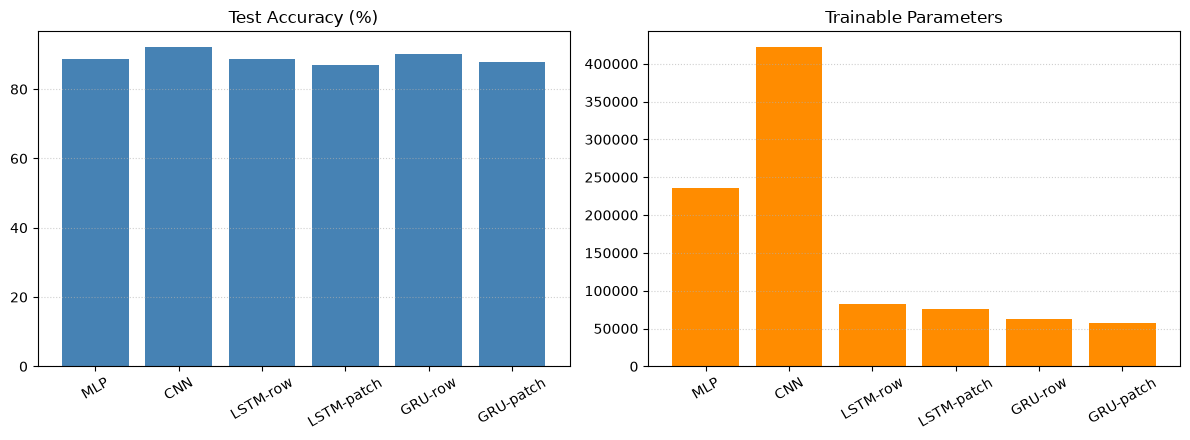

,Model,Original Test Acc (%),Row-Flipped Test Acc (%),Drop (pp)
0,MLP,88.57,19.97,68.60
1,CNN,92.08,20.75,71.33
2,LSTM-row,88.76,18.79,69.97
3,LSTM-patch,87.11,21.56,65.55
4,GRU-row,90.06,21.43,68.63
5,GRU-patch,87.97,22.77,65.20


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
names = df_summary["Model"].tolist()
axes[0].bar(names, df_summary["Test Acc (%)"], color="steelblue")
axes[0].set_title("Test Accuracy (%)")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(True, axis="y", linestyle=":", alpha=0.6)

axes[1].bar(names, df_summary["Params"], color="darkorange")
axes[1].set_title("Trainable Parameters")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(True, axis="y", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "e3_summary_bars_fashion_mnist.png"), dpi=150)
plt.show()

df_order = pd.DataFrame(order_sensitivity)
display(df_order)

## 7. Lưu Kết quả

In [7]:
import json

config_e3 = {
    "dataset": "Fashion-MNIST",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "val_ratio": VAL_RATIO,
    "epochs": EPOCHS,
    "learning_rate": LR,
    "optimizer": "Adam",
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "grad_clip_max_norm": 5.0,
    "sequence_types": ["row", "patch"],
    "patch_size": PATCH_SIZE,
    "device": str(device)
}
with open(os.path.join(OUTPUT_DIR, "config_e3.json"), "w", encoding="utf-8") as f:
    json.dump(config_e3, f, indent=4, ensure_ascii=False)

with open(os.path.join(OUTPUT_DIR, "training_log_e3.json"), "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4)

df_summary.to_csv(os.path.join(OUTPUT_DIR, "summary_results_e3.csv"), index=False)
df_order.to_csv(os.path.join(OUTPUT_DIR, "order_sensitivity_e3.csv"), index=False)
print("Đã lưu thành công config_e3.json, training_log_e3.json, summary_results_e3.csv và order_sensitivity_e3.csv!")

Đã lưu thành công config_e3.json, training_log_e3.json, summary_results_e3.csv và order_sensitivity_e3.csv!
